In [13]:
using Pkg

In [179]:
import XLSX
using DataFrames
using Plots
using Turing
using Distributions
using MCMCChains
using DynamicPPL
using PyCall, RCall

In [15]:
run(`ls`)

AveragedOriginalMeasurements_all_graphs.xlsx
Binned_Energies.xlsx
Data_normalised.xlsx
medicalHeat.ipynb
med_trials_V8.ipynb
med_trials_V8-refactor.ipynb
Untitled.ipynb
UsedDataEntrBin_original.xlsx


Process(`ls`, ProcessExited(0))

In [16]:
UsedDataEntrBin_original = XLSX.readxlsx("Data_normalised.xlsx")

XLSXFile("Data_normalised.xlsx") containing 3 Worksheets
            sheetname size          range        
-------------------------------------------------
                 NRTI 50832x12      A1:L50832    
                NNRTI 50087x12      A1:L50087    
                   PI 50913x12      A1:L50913    


In [17]:
UsedDataEntrBin_original_sheets = XLSX.sheetnames(UsedDataEntrBin_original)

3-element Vector{String}:
 "NRTI"
 "NNRTI"
 "PI"

In [18]:
UsedDataEntrBin_original_PI = UsedDataEntrBin_original["PI"]

50913×12 XLSX.Worksheet: ["PI"](A1:L50913) 

In [19]:
fieldnames( typeof(UsedDataEntrBin_original_PI) )

(:package, :sheetId, :relationship_id, :name, :dimension, :is_hidden, :cache)

In [20]:
UsedDataEntrBin_original_PI.dimension

A1:L50913

In [21]:
#the CASEID is the patient ID and the VISIT is the number of visits previously for that patient
PI_mat = UsedDataEntrBin_original_PI[:]

50913×12 Matrix{Any}:
     "CASEID"    "VISIT"   "VLOAD"     …   "BUN_LF"   "CREALF"   "Energy"
 1004          16         6.92318e-5      0.347826   0.4375     0.98737
 1006           9         0.00421545      0.347826   0.4375     1.00052
 1022           9         4.61546e-5      0.26087    0.433036   0.97401
 1028           9         4.61546e-5      0.333333   0.446429   1.02755
 1031           9         0.000907706  …  0.434783   0.455357   1.06191
 1035           9         4.61546e-5      0.202899   0.4375     0.973948
 1044          16         0.0115233       0.347826   0.441964   1.0166
 1053           9         4.61546e-5      0.304348   0.4375     1.72612
 1061           9         0               0.347826   0.437054   1.00998
 1062          25         4.61546e-5   …  0.318841   0.4375     1.00569
 1065          18         4.61546e-5      0.362319   0.433036   1.01818
 1068           9         0.0153695       0.289855   0.441964   1.40515
    ⋮                                  ⋱

In [22]:
maximum(PI_mat[2:end,3])

1.0

In [23]:
PI_mat_L2 = PI_mat[ 2:end , filter( x-> !(x in [1,2]), 1:size(PI_mat)[2] ) ];

In [24]:
PI_energies = sqrt.( sum( map( row -> row .^ 2  ,  PI_mat_L2 ), dims=2 ) );

In [25]:
size(PI_energies)

(50912, 1)

In [26]:
energy_keys = unique( PI_mat[2:end,2] );
energy_keys;

In [27]:
energy_dict = Dict(key => [] for key in energy_keys);

In [28]:
for key in keys( energy_dict )
    indices = findall( PI_mat[1:end,2] .== key) .- 1
    key_energies = PI_energies[indices]
    push!( energy_dict[key] , key_energies )
end

In [29]:
sum([ length(energy_dict[k][1]) for k in keys(energy_dict) ])

50912

In [30]:
#test = energy_dict[ collect(keys(energy_dict))[1] ]
visit_num_test = 20
test = energy_dict[ visit_num_test ]

1-element Vector{Any}:
 [1.377338215379127, 1.2944887388324744, 1.4037492370798534, 1.9257526784693109, 1.2993292334804298, 1.564731070324242, 1.4231940580517888, 1.4293560876771123, 1.4155968549104458, 1.3860252602860426  …  1.3582386849705028, 1.1934364444231815, 1.4061308412866784, 1.397829158202525, 1.9837699595493201, 1.3723460548364868, 1.4681152112863793, 1.4087708939869898, 1.5210324754841076, 2.048890668916075]

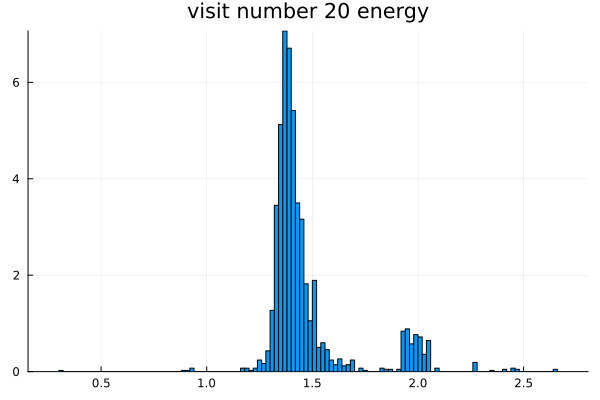

In [110]:
p = histogram( test , title="visit number $visit_num_test energy", legend=false,
                normalized=true)
display(p)

In [118]:
data_dist_sigma = 0.05

0.05

In [119]:

@model function finite_mixture_model(data, K)
    N = length(data)  # Number of data points
    σ = 1.0  # Standard deviation for each component (can be adjusted)

    # Priors for the mixture components
    μ = Vector{Real}(undef, K)
    for k in 1:K
        μ[k] ~ Normal(0, data_dist_sigma)
    end
    # Dirichlet prior for the mixing proportions
    θ ~ Dirichlet(ones(K))
    # Mixture model
    for i in 1:N
        z = rand(Categorical(θ))
        @addlogprob! logpdf(Categorical(θ), z)
        
        data[i] ~ Normal(μ[z], σ)
    end
end

finite_mixture_model (generic function with 2 methods)

In [120]:
data = test[1]  # Replace with your actual data
# Number of mixture components
K = 4  # Adjust this based on your data
# Instantiate the model
model = finite_mixture_model(data, K)
# Sample from the posterior
chain = sample(model, NUTS(), 1000)

┌ Info: Found initial step size
└   ϵ = 0.05
Sampling: 100%|█████████████████████████████████████████| Time: 0:37:58


Chains MCMC chain (1000×20×1 Array{Float64, 3}):

Iterations        = 501:1:1500
Number of chains  = 1
Samples per chain = 1000
Wall duration     = 2282.21 seconds
Compute duration  = 2282.21 seconds
parameters        = μ[1], μ[2], μ[3], μ[4], θ[1], θ[2], θ[3], θ[4]
internals         = lp, n_steps, is_accept, acceptance_rate, log_density, hamiltonian_energy, hamiltonian_energy_error, max_hamiltonian_energy_error, tree_depth, numerical_error, step_size, nom_step_size

Summary Statistics
  parameters      mean       std      mcse   ess_bulk   ess_tail      rhat   e ⋯
      Symbol   Float64   Float64   Float64    Float64    Float64   Float64     ⋯

        μ[1]    0.1964    0.0000       NaN        NaN        NaN       NaN     ⋯
        μ[2]    1.1429    0.0000    0.0000        NaN        NaN       NaN     ⋯
        μ[3]    0.8179    0.0000    0.0000        NaN        NaN       NaN     ⋯
        μ[4]    0.6126    0.0000       NaN        NaN        NaN       NaN     ⋯
        θ[1]    0.0379

In [121]:
# Number of components in your model
# Initialize arrays to store samples
μ_samples = Array{Float64}(undef, length(chain), K)
θ_samples = Array{Float64}(undef, length(chain), K)

# Extract samples for each component
for k in 1:K
    μ_samples[:, k] = get(chain, Symbol("μ[$k]"))[1].data[:, 1]
    θ_samples[:, k] = get(chain, Symbol("θ[$k]"))[1].data[:, 1]
end

In [126]:
# Example: Select first few samples
num_samples_to_use = 100  # Adjust as needed
μ_selected = μ_samples[1:num_samples_to_use, :]
θ_selected = θ_samples[1:num_samples_to_use, :]

100×4 Matrix{Float64}:
 0.0378687  0.599364  0.228128  0.134639
 0.0378687  0.599364  0.228128  0.134639
 0.0378687  0.599364  0.228128  0.134639
 0.0378687  0.599364  0.228128  0.134639
 0.0378687  0.599364  0.228128  0.134639
 0.0378687  0.599364  0.228128  0.134639
 0.0378687  0.599364  0.228128  0.134639
 0.0378687  0.599364  0.228128  0.134639
 0.0378687  0.599364  0.228128  0.134639
 0.0378687  0.599364  0.228128  0.134639
 0.0378687  0.599364  0.228128  0.134639
 0.0378687  0.599364  0.228128  0.134639
 0.0378687  0.599364  0.228128  0.134639
 ⋮                              
 0.0378687  0.599364  0.228128  0.134639
 0.0378687  0.599364  0.228128  0.134639
 0.0378687  0.599364  0.228128  0.134639
 0.0378687  0.599364  0.228128  0.134639
 0.0378687  0.599364  0.228128  0.134639
 0.0378687  0.599364  0.228128  0.134639
 0.0378687  0.599364  0.228128  0.134639
 0.0378687  0.599364  0.228128  0.134639
 0.0378687  0.599364  0.228128  0.134639
 0.0378687  0.599364  0.228128  0.134639
 

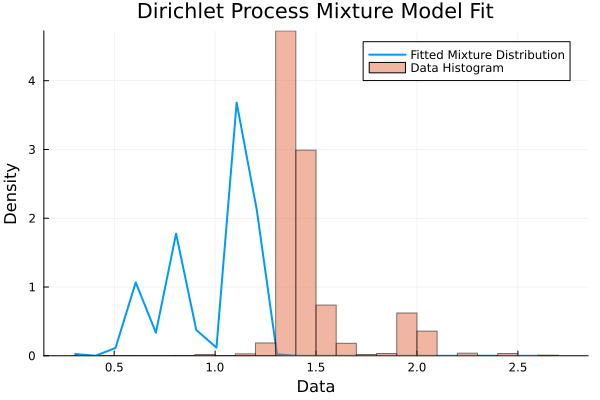

In [127]:
data = test[1]
# Function to compute the density of the mixture model at a given point
function mixture_density(x, μ_samples, θ_samples)
    K = size(μ_samples, 2)
    density = 0.0
    for k in 1:K
        component_density = mean([pdf(Normal(μ_samples[i, k], data_dist_sigma), x) * θ_samples[i, k] for i in 1:size(μ_samples, 1)])
        density += component_density
    end
    return density
end

# Generate points for plotting
x_range = minimum(data):0.1:maximum(data)
y_range = [mixture_density(x, μ_samples, θ_samples) for x in x_range]

# Plotting
plot(x_range, y_range, label="Fitted Mixture Distribution", lw=2)
histogram!(data, bins=30, alpha=0.5, label="Data Histogram", normalized=true)
xlabel!("Data")
ylabel!("Density")
title!("Dirichlet Process Mixture Model Fit")



In [194]:
R"library(dirichletprocess)"

RObject{StrSxp}
 [1] "dirichletprocess" "DirichletReg"     "Formula"          "stats"           
 [5] "graphics"         "grDevices"        "utils"            "datasets"        
 [9] "methods"          "base"            


In [261]:
R"""
fit_and_get_density = function(data, points) {
    # Create and fit a Dirichlet process model
    # dp_fit <- DirichletProcessGaussian(data, alphaPriors = c(alpha, alpha))
    dp_fit <- DirichletProcessGaussian(data)
    dp_fit <- Fit(dp_fit, 200)  # Fit the model with a specified number of iterations

    # Get the likelihood function for the fitted model
    likelihood_func <- LikelihoodFunction(dp_fit)

    # Calculate the likelihood (proxy for density) at each point
    densities = sapply(points, function(point) {
        likelihood_func(point)
    })

    return(densities)
}
"""

RObject{ClosSxp}
function (data, points) 
{
    dp_fit <- DirichletProcessGaussian(data)
    dp_fit <- Fit(dp_fit, 200)
    likelihood_func <- LikelihoodFunction(dp_fit)
    densities = sapply(points, function(point) {
        likelihood_func(point)
    })
    return(densities)
}


In [291]:
# julia_data = rand(1000);
julia_data = vcat( [rand(100) .+ 5]..., [rand(100) .+ 20]... )
x_points = collect(0 : 0.1 : 30);
@rput julia_data
@rput x_points;
dpfit = R"fit_and_get_density(julia_data, x_points)"
Rdensities = rcopy( dpfit )

301-element Vector{Float64}:
 4.223350847783997e-15
 1.3106504648476748e-14
 3.9862378246971834e-14
 1.1879480788022343e-13
 3.468568750867314e-13
 9.922109150365673e-13
 2.7806760459420857e-12
 7.634589544425667e-12
 2.0535632764895098e-11
 5.411488171402974e-11
 1.397047390413933e-10
 3.533386544672063e-10
 8.755009922980512e-10
 ⋮
 0.00010921126371297527
 9.343866417914192e-5
 7.979966863965623e-5
 6.802849033075688e-5
 5.7888974622108576e-5
 4.917180596005851e-5
 4.169190501405675e-5
 3.528601371025656e-5
 2.981046399407e-5
 2.5139124653690142e-5
 2.1161519331548376e-5
 1.7781107921870044e-5

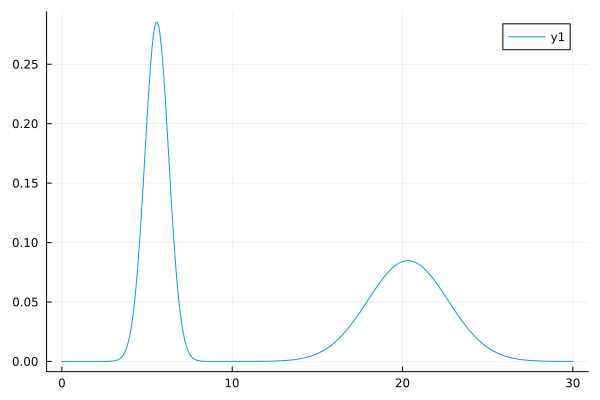

In [292]:
plot(x_points, Rdensities )

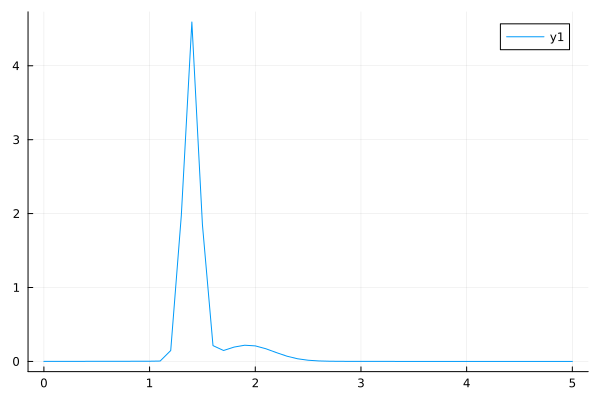

In [293]:
julia_data = data
x_points = collect(0 : 0.1 : 5);
@rput julia_data
@rput x_points;
dpfit = R"fit_and_get_density(julia_data, x_points)"
Rdensities = rcopy( dpfit )
plot(x_points, Rdensities )